In [1]:
.libPaths(c('/home/jbos/.conda/envs/vcfR','/home/jbos/.conda/envs/vcfR/lib/R/library','/software/apps/r/conda3-4.4.1/lib/R/library','/home/jbos/R/x86_64-conda-linux-gnu-library/4.4'))

In [5]:
#Load required packages
library(adegenet)
library(hierfstat)
library(tidyverse)
library(vegan)
library(vcfR)
library(sp)
library(sf)

In [3]:
#Calculate great circle distances from lat/lons
wide_dists <- function(sites){
    x<-st_as_sf(sites,coords=c('LONGITUDE','LATITUDE'))
    x<-st_set_crs(x,4326)
    d <- st_distance(x)
    colnames(d)<-sites$Name
    rownames(d)<-sites$Name
    d<-as.data.frame(d)
    return(d)
}

In [4]:
#Calculate great circle distances from lat/lons
wide_dists2 <- function(sites){
    x<-st_as_sf(sites,coords=c('lon_flat','lat_flat'))
    x<-st_set_crs(x,4326)
    d <- st_distance(x)
    colnames(d)<-sites$release_flat
    rownames(d)<-sites$release_flat
    d<-as.data.frame(d)
    return(d)
}

In [6]:
#Inputs: wide form FSTs and dataframe of individuals corresponding to each population
#Output: long form FSTs. Columns: siteA	siteB	fst	siteA_counts	siteB_counts	mean_counts
fst_transform<-function(fsts,indpops){
    fst_long<-pivot_longer(fsts,cols=colnames(fsts)[2:length(colnames(fsts))],names_to='siteB',values_to='fst')
    colnames(fst_long)<-c('siteA','siteB','fst')
    fst_long<-fst_long[!is.nan(fst_long$fst),]
    dum<-as.data.frame(table(indpops$Population))
    colnames(dum)<-c('siteA','siteA_counts')
    fst_long<-left_join(fst_long,dum,by='siteA')
    colnames(dum)<-c('siteB','siteB_counts')
    fst_long<-left_join(fst_long,dum,by='siteB')
    fst_long$mean_counts<-rowMeans(as.data.frame(cbind(fst_long$siteA_counts,fst_long$siteB_counts)))
    return(fst_long)
}

In [7]:
#Inputs: wide form FSTs and dataframe of individuals corresponding to each population
#Output: wide form linearized FSTs for Mantel tests and figures
linear_fsts<-function(wide_fsts){
  wide_fsts<-as.data.frame(wide_fsts)
  rownames(wide_fsts)<-wide_fsts[,1]
  wide_fsts<-wide_fsts[,-1]
  fst_lin <- wide_fsts/(1-wide_fsts)
  return(fst_lin)
}

In [8]:
#Inputs: wide form FSTs and dataframe of individuals corresponding to each population
#Output: wide form linearized FSTs for Mantel tests and figures
linear_fsts2<-function(wide_fsts){
  wide_fsts<-as.data.frame(wide_fsts)
  fst_lin <- wide_fsts/(1-wide_fsts)
  return(fst_lin)
}

In [9]:
#Inputs: wide form linearized FSTs and wide form distances for each cryptic taxon
#Outputs: long form dataframe with columns SiteA	SiteB	Lin_FST	Distance_m
fst_dist_join<-function(fsts_linear, distances){
    fsts_linear$SiteA<-rownames(fsts_linear)
    distances$SiteA<-rownames(distances)
    fst_lin_lon<-pivot_longer(data=fsts_linear,cols=colnames(fsts_linear)[!(colnames(fsts_linear) %in% 'SiteA')],names_to='SiteB',values_to='Lin_FST')
    dists_lon<-pivot_longer(data=distances,cols=colnames(distances)[!(colnames(distances) %in% 'SiteA')],names_to='SiteB',values_to='Distance_m')
    mer<-inner_join(fst_lin_lon,dists_lon)
    mer<-mer[mer$SiteA!=mer$SiteB,]
    mer$Distance_m<-as.numeric(mer$Distance_m)
    mer_uniquerows <- mer %>% distinct(Distance_m, .keep_all = TRUE)
    return(mer_uniquerows)
    }

In [10]:
#Count individuals per population
make_counts<-function(inds_per_pop){
    dummy<-as.data.frame(matrix(nrow=length(unique(inds_per_pop$Population))))
    dummy[,1]<-unique(inds_per_pop$Population)
    dummy[,2]<-table(inds_per_pop$Population)
    colnames(dummy)<-c('pop','count')
    return(dummy)
    }

In [11]:
#Input: FSTs, vector of number of individuals per population, minimum number of individuals per popualtion
#Output: Matrix of FSTs including only populations above the minimum size
fst_trim_by_N<-function(fsts,inds_per_pop,min_n){
    fsts<-as.data.frame(fsts)
    fst_trim<-fsts[fsts$...1 %in% as.data.frame(table(inds_per_pop$Population)[table(inds_per_pop$Population)>(min_n-1)])$Var1,]
    fst_trim<-fst_trim[,colnames(fst_trim)%in% as.data.frame(table(inds_per_pop$Population)[table(inds_per_pop$Population)>(min_n-1)])$Var1]
    rownames(fst_trim)<-colnames(fst_trim)
    return(fst_trim)
    }

In [12]:
#Import site locations with lat/lons
sites <- read.csv('/home/jbos/Atenuis_Philippines/metadat/all_Atenuis_sites.csv')
metadat<-read.csv('/home/jbos/Atenuis_Philippines/metadat/metadata_shoredist.csv')

In [13]:
all_snps <- read.vcfR("/scratch/jbos/combined_snps/pruned_snps10.vcf")

Scanning file to determine attributes.
File attributes:
  meta lines: 289
  header_line: 290
  variant count: 1846
  column count: 247
Meta line 289 read in.
All meta lines processed.
gt matrix initialized.
Character matrix gt created.
  Character matrix gt rows: 1846
  Character matrix gt cols: 247
  skip: 0
  nrows: 1846
  row_num: 0
Processed variant: 1846
All variants processed


In [14]:
#Convert to genind format
genind_snps <- vcfR2genind(all_snps)

In [15]:
#Read in eigenvectors and eigenvalues created with Plink2
eigenval <- read.table("/scratch/jbos/combined_snps/pca_pruned10.eigenval", header = FALSE, sep = " ")
eigenvec <- read.table("/scratch/jbos/combined_snps/pca_pruned10.eigenvec", header = FALSE, sep = "\t")

In [17]:
#Rename columns
colnames(eigenvec) <-c ('Sample_ID', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10')

In [18]:
#Calculate % of variation accounted for by each of top five principal components
varPC1 <- (eigenval[1,1] / sum(eigenval$V1))*100
varPC2 <- (eigenval[2,1] / sum(eigenval$V1))*100
varPC3 <- (eigenval[3,1] / sum(eigenval$V1))*100
varPC4 <- (eigenval[4,1] / sum(eigenval$V1))*100
varPC5 <- (eigenval[5,1] / sum(eigenval$V1))*100

In [19]:
#Look at percent variation for top 5 PCs
varPC1
varPC2
varPC3
varPC4
varPC5

[1] 30.3331

[1] 20.5227

[1] 15.34015

[1] 9.556766

[1] 4.910614

In [20]:
#Create 'island' value for Cebu vs. Leyte province (note that Camotes are in Cebu province)
#Create 'Pop' variable for sampling site
eigenvec$Island <- substr(eigenvec$Sample_ID,start=1,stop=3)
eigenvec$Pop <- substr(eigenvec$Sample_ID,start=1,stop=5)

In [21]:
#Join variables
metadat_merge<-inner_join(eigenvec,metadat)

Joining with `by = join_by(Sample_ID)`


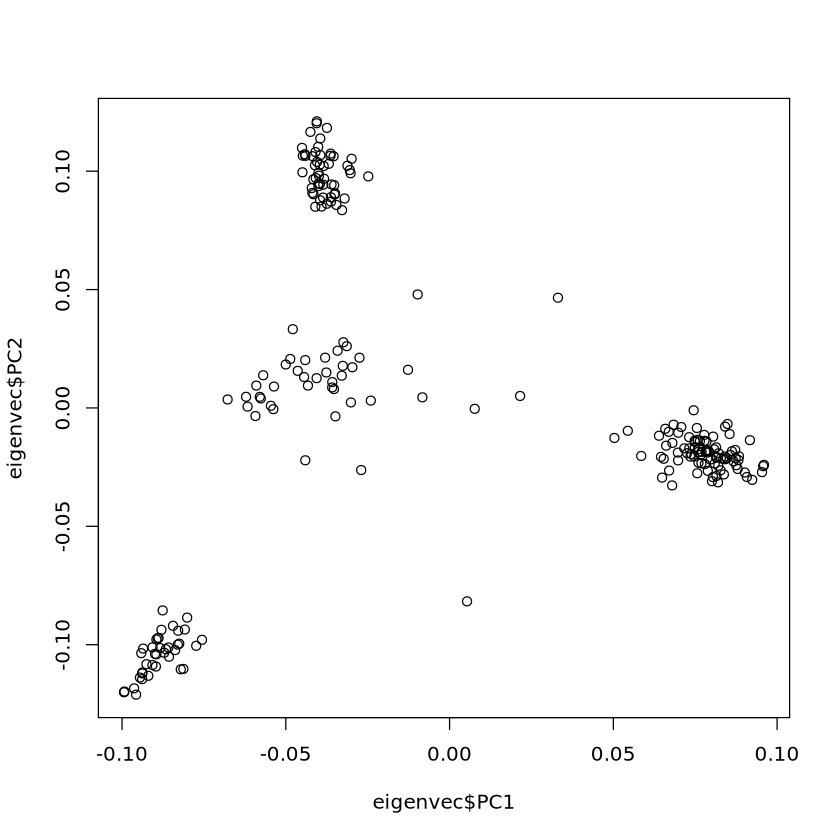

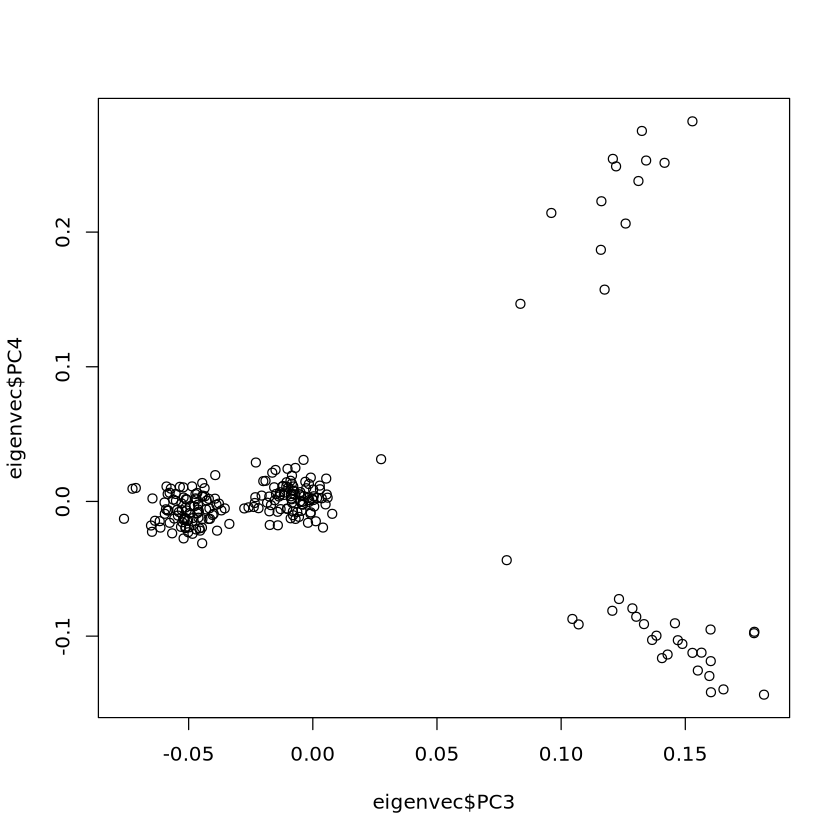

In [22]:
#Visualize data in PC space
plot(eigenvec$PC1,eigenvec$PC2)
plot(eigenvec$PC3,eigenvec$PC4)

Choose the number of clusters (>=2): 

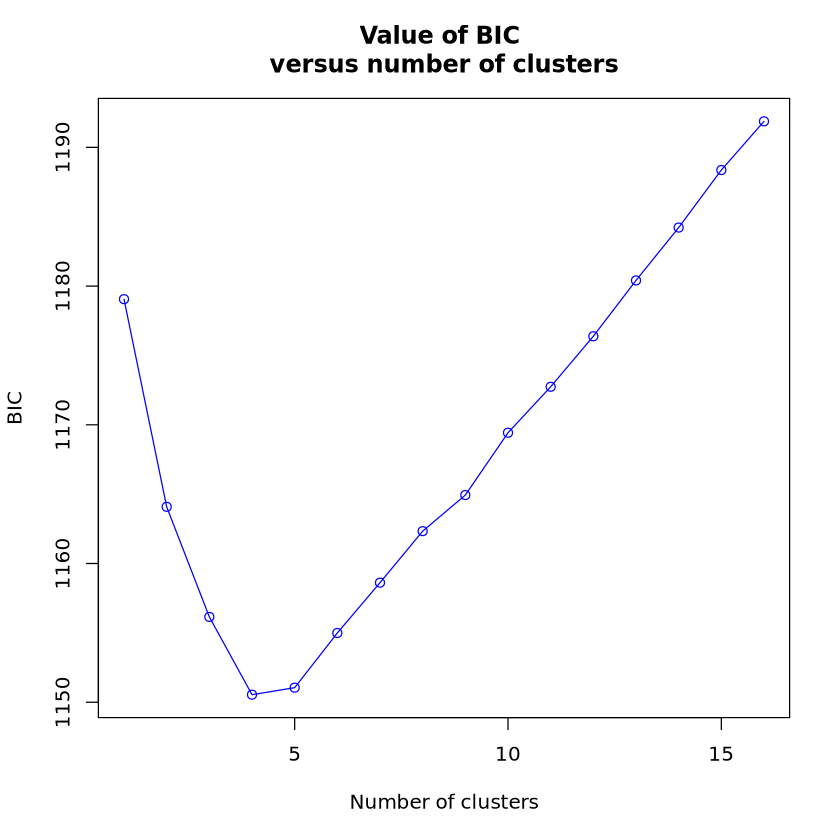

In [152]:
#Use DFA to find number of distinct clusters
set.seed(42)
grps<-find.clusters(genind_snps,max.n.clust=16,n.pca=500)

In [153]:
#Check cross validation stats
grps$Kstat

K=1      K=2      K=3      K=4      K=5      K=6      K=7      K=8 
1179.058 1164.087 1156.151 1150.545 1151.049 1154.993 1158.618 1162.333 
     K=9     K=10     K=11     K=12     K=13     K=14     K=15     K=16 
1164.934 1169.428 1172.741 1176.384 1180.406 1184.218 1188.365 1191.876

In [154]:
#Find clusters
set.seed(42)
grp<-find.clusters(genind_snps,n.clust=4,n.pca=500)
table(grp$grp)


 1  2  3  4 
91 38 54 40 

In [155]:
taxon1<-names(grp$grp[grp$grp==1])
write.csv(taxon1,file='/home/jbos/Philippines_revisions/taxon1_missingness.csv')

taxon2<-names(grp$grp[grp$grp==2])
write.csv(taxon2,file='/home/jbos/Philippines_revisions/taxon2_missingness.csv')

taxon3<-names(grp$grp[grp$grp==3])
write.csv(taxon3,file='/home/jbos/Philippines_revisions/taxon3_missingness.csv')

taxon4<-names(grp$grp[grp$grp==4])
write.csv(taxon4,file='/home/jbos/Philippines_revisions/taxon4_missingness.csv')

In [16]:
inds1<-read.csv('/home/jbos/Atenuis_Philippines/other_data/taxa1_inds.csv')[,2]
inds2<-read.csv('/home/jbos/Atenuis_Philippines/other_data/taxa2_inds.csv')[,2]
inds3<-read.csv('/home/jbos/Atenuis_Philippines/other_data/taxa3_inds.csv')[,2]
inds4<-read.csv('/home/jbos/Atenuis_Philippines/other_data/taxa4_inds.csv')[,2]

In [17]:
table(taxon1 %in% inds1)
table(taxon1 %in% inds2)
table(taxon1 %in% inds3)
table(taxon1 %in% inds4)

ERROR: Error: object 'taxon1' not found


In [158]:
table(taxon2 %in% inds1)
table(taxon2 %in% inds2)
table(taxon2 %in% inds3)
table(taxon2 %in% inds4)


FALSE 
   38 


FALSE 
   38 


FALSE 
   38 


TRUE 
  38 

In [159]:
table(taxon3 %in% inds1)
table(taxon3 %in% inds2)
table(taxon3 %in% inds3)
table(taxon3 %in% inds4)


FALSE 
   54 


TRUE 
  54 


FALSE 
   54 


FALSE 
   54 

In [32]:
table(taxon4 %in% inds1)
table(taxon4 %in% inds2)
table(taxon4 %in% inds3)
table(taxon4 %in% inds4)


FALSE 
   40 


FALSE 
   40 


TRUE 
  40 


FALSE 
   40 

In [18]:
#Import SNPs for each cryptic taxon
setwd('/scratch/jbos/')
spp1<-read.vcfR("spp1/pruned_snps10.vcf")
spp2<-read.vcfR("spp2/pruned_snps10.vcf")
spp3<-read.vcfR("spp3/pruned_snps10.vcf")
spp4<-read.vcfR("spp4/pruned_snps10.vcf")

Scanning file to determine attributes.
File attributes:
  meta lines: 361
  header_line: 362
  variant count: 2292
  column count: 90
Meta line 361 read in.
All meta lines processed.
gt matrix initialized.
Character matrix gt created.
  Character matrix gt rows: 2292
  Character matrix gt cols: 90
  skip: 0
  nrows: 2292
  row_num: 0
Processed variant: 2292
All variants processed
Scanning file to determine attributes.
File attributes:
  meta lines: 339
  header_line: 340
  variant count: 1678
  column count: 63
Meta line 339 read in.
All meta lines processed.
gt matrix initialized.
Character matrix gt created.
  Character matrix gt rows: 1678
  Character matrix gt cols: 63
  skip: 0
  nrows: 1678
  row_num: 0
Processed variant: 1678
All variants processed
Scanning file to determine attributes.
File attributes:
  meta lines: 313
  header_line: 314
  variant count: 1213
  column count: 50
Meta line 313 read in.
All meta lines processed.
gt matrix initialized.
Character matrix gt created.

In [19]:
#Convert VCF files to genind
genind1 <- vcfR2genind(spp1)
genind2 <- vcfR2genind(spp2)
genind3 <- vcfR2genind(spp3)
genind4 <- vcfR2genind(spp4)

In [20]:
#Get lists of individuals for each cryptic taxon
taxa1_inds<-rownames(genind1@tab)
taxa2_inds<-rownames(genind2@tab)
taxa3_inds<-rownames(genind3@tab)
taxa4_inds<-rownames(genind4@tab)

In [21]:
#Add population factors to each genind. Here, we define a sampling site as a population
genind1@pop <-as.factor(unlist(lapply(strsplit(rownames(genind1$tab),"_"), head, 1)))
genind2@pop <-as.factor(unlist(lapply(strsplit(rownames(genind2$tab),"_"), head, 1)))
genind3@pop <-as.factor(unlist(lapply(strsplit(rownames(genind3$tab),"_"), head, 1)))
genind4@pop <-as.factor(unlist(lapply(strsplit(rownames(genind4$tab),"_"), head, 1)))

In [22]:
#For each taxon, keep only sites including at least one individual from that taxon
sites1<-sites[sites$Name %in% unique(genind1@pop),]
sites2<-sites[sites$Name %in% unique(genind2@pop),]
sites3<-sites[sites$Name %in% unique(genind3@pop),]
sites4<-sites[sites$Name %in% unique(genind4@pop),]

In [23]:
#Convert genind to hierfstat form to calculate FSTs
hstat1<-genind2hierfstat(genind1,pop=genind1@pop)
hstat2<-genind2hierfstat(genind2,pop=genind2@pop)
hstat3<-genind2hierfstat(genind3,pop=genind3@pop)
hstat4<-genind2hierfstat(genind4,pop=genind4@pop)

In [24]:
#Make wide form dataframes of distance between sites
dists1<-wide_dists(sites1)
dists2<-wide_dists(sites2)
dists3<-wide_dists(sites3)
dists4<-wide_dists(sites4)

In [25]:
#Take log of distances for Mantel tests
log_dists1<-log(dists1)
log_dists2<-log(dists2)
log_dists3<-log(dists3)
log_dists4<-log(dists4)

In [26]:
#Make sf object out of points(this will be useful later)
sites_sf<-st_as_sf(sites,coords=c('LONGITUDE','LATITUDE'))
sites_sf<-st_set_crs(sites_sf,4326)
sitepoints<-st_combine(sites_sf)
sites_proj<-st_transform(sitepoints,crs=9834)

In [48]:
#Calculate pairwise FSTs with confidence intervals within each cryptic taxon
fst_1<-pairwise.WCfst(hstat1)
fst_2<-pairwise.WCfst(hstat2)
fst_3<-pairwise.WCfst(hstat3)
fst_4<-pairwise.WCfst(hstat4)

In [ ]:
#Write pairwise FSTs to FST
setwd('/home/jbos/Philippines_revisions')
write.csv(fst_1,'fst_1_missing10.csv',row.names=TRUE)
write.csv(fst_2,'fst_2_missing10.csv',row.names=TRUE)
write.csv(fst_3,'fst_3_missing10.csv',row.names=TRUE)
write.csv(fst_4,'fst_4_missing10.csv',row.names=TRUE)

In [27]:
#Alternatively, read in pairwise FSTs from csv
setwd('/home/jbos/Philippines_revisions')
fst1<-read_csv('fst_1_missing10.csv',show_col_types = FALSE)
fst2<-read_csv('fst_2_missing10.csv',show_col_types = FALSE)
fst3<-read_csv('fst_3_missing10.csv',show_col_types = FALSE)
fst4<-read_csv('fst_4_missing10.csv',show_col_types = FALSE)

New names:
• `` -> `...1`
New names:
• `` -> `...1`
New names:
• `` -> `...1`
New names:
• `` -> `...1`


In [28]:
#Make dataframes of individuals and corresponding populations for each taxon
inds_per_pop1<-as.data.frame(cbind(rownames(genind1@tab),as.character(genind1@pop)))
colnames(inds_per_pop1)<-c("Individual","Population")

inds_per_pop2<-as.data.frame(cbind(rownames(genind2@tab),as.character(genind2@pop)))
colnames(inds_per_pop2)<-c("Individual","Population")

inds_per_pop3<-as.data.frame(cbind(rownames(genind3@tab),as.character(genind3@pop)))
colnames(inds_per_pop3)<-c("Individual","Population")

inds_per_pop4<-as.data.frame(cbind(rownames(genind4@tab),as.character(genind4@pop)))
colnames(inds_per_pop4)<-c("Individual","Population")

In [29]:
#Make site counts dataframe to count individuals per taxon per site
c1<-make_counts(inds_per_pop1)
c2<-make_counts(inds_per_pop2)
c3<-make_counts(inds_per_pop3)
c4<-make_counts(inds_per_pop4)

site_counts<-full_join(c1,c2,by='pop')
site_counts<-full_join(site_counts,c3,by='pop')
site_counts<-full_join(site_counts,c4,by='pop')
colnames(site_counts)<-c('pop','taxon1','taxon2','taxon3','taxon4')
site_counts[is.na(site_counts)] <- 0
write.csv(site_counts,'site_counts_missingness.csv')

In [30]:
#Transform FSTs to long form and add variables for number of individuals in each population
fst1_long<-fst_transform(fst1,inds_per_pop1)
fst2_long<-fst_transform(fst2,inds_per_pop2)
fst3_long<-fst_transform(fst3,inds_per_pop3)
fst4_long<-fst_transform(fst4,inds_per_pop4)

In [65]:
clad_sites1_1D<-read.csv('/home/jbos/Philippines_revisions/clad_sites1_1D.csv')[,2]
clad_sites2_1D<-read.csv('/home/jbos/Philippines_revisions/clad_sites2_1D.csv')[,2]
clad_sites3_1D<-read.csv('/home/jbos/Philippines_revisions/clad_sites3_1D.csv')[,2]
clad_sites4_1D<-read.csv('/home/jbos/Philippines_revisions/clad_sites4_1D.csv')[,2]

In [66]:
clad_sites1_2D<-read.csv('/home/jbos/Philippines_revisions/clad_sites1_2D.csv')[,2]
clad_sites2_2D<-read.csv('/home/jbos/Philippines_revisions/clad_sites2_2D.csv')[,2]
clad_sites3_2D<-read.csv('/home/jbos/Philippines_revisions/clad_sites3_2D.csv')[,2]
clad_sites4_2D<-read.csv('/home/jbos/Philippines_revisions/clad_sites4_2D.csv')[,2]

In [73]:
#Create matrix of FSTs only including populations where N>=1
fst_trim1<-fst_trim_by_N(fst1,inds_per_pop1,1)
fst_trim1<-fst_trim1[rownames(fst_trim1) %in% clad_sites1_2D, colnames(fst_trim1) %in% clad_sites1_2D]

fst_trim2<-fst_trim_by_N(fst2,inds_per_pop2,1)
fst_trim2<-fst_trim2[rownames(fst_trim2) %in% clad_sites2_2D, colnames(fst_trim2) %in% clad_sites2_2D]

fst_trim3<-fst_trim_by_N(fst3,inds_per_pop3,1)
fst_trim3<-fst_trim3[rownames(fst_trim3) %in% clad_sites3_2D, colnames(fst_trim3) %in% clad_sites3_2D]

fst_trim4<-fst_trim_by_N(fst4,inds_per_pop4,1)
fst_trim4<-fst_trim4[rownames(fst_trim4) %in% clad_sites4_2D, colnames(fst_trim4) %in% clad_sites4_2D]

In [74]:
#Create matrices of pairwise distances to correspond to sites with sufficiently high Ns.
dists_trim1<-dists1[rownames(dists1) %in% colnames(fst_trim1),colnames(dists1) %in% colnames(fst_trim1)]
dists_trim2<-dists2[rownames(dists2) %in% colnames(fst_trim2),colnames(dists2) %in% colnames(fst_trim2)]
dists_trim3<-dists3[rownames(dists3) %in% colnames(fst_trim3),colnames(dists3) %in% colnames(fst_trim3)]
dists_trim4<-dists4[rownames(dists4) %in% colnames(fst_trim4),colnames(dists4) %in% colnames(fst_trim4)]

In [75]:
#Take log of distances for Mantel tests
log_dists1_trim<-log(dists_trim1)
log_dists2_trim<-log(dists_trim2)
log_dists3_trim<-log(dists_trim3)
log_dists4_trim<-log(dists_trim4)

In [76]:
#Convert wide form FSTs to linearized wide form FSTs for use in Mantel test, excluding low N sites
fst_lin1_trim<-as.data.frame(linear_fsts2(fst_trim1))
fst_lin2_trim<-as.data.frame(linear_fsts2(fst_trim2))
fst_lin3_trim<-as.data.frame(linear_fsts2(fst_trim3))
fst_lin4_trim<-as.data.frame(linear_fsts2(fst_trim4))

In [77]:
#Create dataframe of sites on Cebu island (exluding Camotes, which were originally labeled as Cebu)
Ceb_real <- sites[sites$LONGITUDE<124.25,3]

In [90]:
#Create matrices of FSTs from Cebu only, sites with 2+ individuals
fst_Cebu1_trim<-fst_lin1_trim[rownames(fst_lin1_trim) %in% Ceb_real, colnames(fst_lin1_trim) %in% Ceb_real]
fst_Cebu2_trim<-fst_lin2_trim[rownames(fst_lin2_trim) %in% Ceb_real, colnames(fst_lin2_trim) %in% Ceb_real]
fst_Cebu3_trim<-fst_lin3_trim[rownames(fst_lin3_trim) %in% Ceb_real, colnames(fst_lin3_trim) %in% Ceb_real]
fst_Cebu4_trim<-fst_lin4_trim[rownames(fst_lin4_trim) %in% Ceb_real, colnames(fst_lin4_trim) %in% Ceb_real]

fst_Cebu1_trim<-fst_Cebu1_trim[rownames(fst_Cebu1_trim) %in% clad_sites1_1D, colnames(fst_Cebu1_trim) %in% clad_sites1_1D]
fst_Cebu2_trim<-fst_Cebu2_trim[rownames(fst_Cebu2_trim) %in% clad_sites2_1D, colnames(fst_Cebu2_trim) %in% clad_sites2_1D]
fst_Cebu3_trim<-fst_Cebu3_trim[rownames(fst_Cebu3_trim) %in% clad_sites3_1D, colnames(fst_Cebu3_trim) %in% clad_sites3_1D]
fst_Cebu4_trim<-fst_Cebu4_trim[rownames(fst_Cebu4_trim) %in% clad_sites4_1D, colnames(fst_Cebu4_trim) %in% clad_sites4_1D]

In [91]:
#Create matrices of pairwise distances from Cebu only, sites with 2+ individuals
dists_Cebu1_trim<-dists_trim1[rownames(dists_trim1) %in% Ceb_real, colnames(dists_trim1) %in% Ceb_real]
dists_Cebu2_trim<-dists_trim2[rownames(dists_trim2) %in% Ceb_real, colnames(dists_trim2) %in% Ceb_real]
dists_Cebu3_trim<-dists_trim3[rownames(dists_trim3) %in% Ceb_real, colnames(dists_trim3) %in% Ceb_real]
dists_Cebu4_trim<-dists_trim4[rownames(dists_trim4) %in% Ceb_real, colnames(dists_trim4) %in% Ceb_real]

In [92]:
#Merge wide form linearized FSTs and wide form distances to long form dataframes of linearized FSTs and pairwise distances
merge1_trim<-fst_dist_join(fst_lin1_trim,dists1)
merge2_trim<-fst_dist_join(fst_lin2_trim,dists2)
merge3_trim<-fst_dist_join(fst_lin3_trim,dists3)
merge4_trim<-fst_dist_join(fst_lin4_trim,dists4)

Joining with `by = join_by(SiteA, SiteB)`
Joining with `by = join_by(SiteA, SiteB)`
Joining with `by = join_by(SiteA, SiteB)`
Joining with `by = join_by(SiteA, SiteB)`


In [93]:
#Create datasets with Cebu only
merge1_Ceb<-fst_dist_join(fst_Cebu1_trim,dists_Cebu1_trim)
merge2_Ceb<-fst_dist_join(fst_Cebu2_trim,dists_Cebu2_trim)
merge3_Ceb<-fst_dist_join(fst_Cebu3_trim,dists_Cebu3_trim)
merge4_Ceb<-fst_dist_join(fst_Cebu4_trim,dists_Cebu4_trim)

Joining with `by = join_by(SiteA, SiteB)`
Joining with `by = join_by(SiteA, SiteB)`
Joining with `by = join_by(SiteA, SiteB)`
Joining with `by = join_by(SiteA, SiteB)`


In [94]:
#Calculate distances, 1D
merge1_Ceb_trim<-merge1_trim[(merge1_trim$SiteA %in% Ceb_real) & (merge1_trim$SiteB %in% Ceb_real),]
merge2_Ceb_trim<-merge2_trim[(merge2_trim$SiteA %in% Ceb_real) & (merge2_trim$SiteB %in% Ceb_real),]
merge3_Ceb_trim<-merge3_trim[(merge3_trim$SiteA %in% Ceb_real) & (merge3_trim$SiteB %in% Ceb_real),]
merge4_Ceb_trim<-merge4_trim[(merge4_trim$SiteA %in% Ceb_real) & (merge4_trim$SiteB %in% Ceb_real),]

In [95]:
#Calculate log distances, 2D
merge1_trim$Dist_log<-log(merge1_trim$Distance_m)
merge2_trim$Dist_log<-log(merge2_trim$Distance_m)
merge3_trim$Dist_log<-log(merge3_trim$Distance_m)
merge4_trim$Dist_log<-log(merge4_trim$Distance_m)

In [96]:
#Calculate standard errors of IBD slopes in one and two dimensions for each taxon. 
se1_trim<-summary(lm(Lin_FST ~ Dist_log,dat=merge1_trim))$coefficients[2,2]
se2_trim<-summary(lm(Lin_FST ~ Dist_log,dat=merge2_trim))$coefficients[2,2]
se3_trim<-summary(lm(Lin_FST ~ Dist_log,dat=merge3_trim))$coefficients[2,2]
se4_trim<-summary(lm(Lin_FST ~ Dist_log,dat=merge4_trim))$coefficients[2,2]

se1_Ceb_trim<-summary(lm(Lin_FST ~ Distance_m,dat=merge1_Ceb_trim))$coefficients[2,2]
se2_Ceb_trim<-summary(lm(Lin_FST ~ Distance_m,dat=merge2_Ceb_trim))$coefficients[2,2]
se3_Ceb_trim<-summary(lm(Lin_FST ~ Distance_m,dat=merge3_Ceb_trim))$coefficients[2,2]
se4_Ceb_trim<-summary(lm(Lin_FST ~ Distance_m,dat=merge4_Ceb_trim))$coefficients[2,2]

In [97]:
#Calculate point estimates of slopes in one and two dimensions
m1_trim<-summary(lm(Lin_FST ~ Dist_log,dat=merge1_trim))$coefficients[2,1]
m2_trim<-summary(lm(Lin_FST ~ Dist_log,dat=merge2_trim))$coefficients[2,1]
m3_trim<-summary(lm(Lin_FST ~ Dist_log,dat=merge3_trim))$coefficients[2,1]
m4_trim<-summary(lm(Lin_FST ~ Dist_log,dat=merge4_trim))$coefficients[2,1]

m1_Ceb_trim<-summary(lm(Lin_FST ~ Distance_m,dat=merge1_Ceb_trim))$coefficients[2,1]
m2_Ceb_trim<-summary(lm(Lin_FST ~ Distance_m,dat=merge2_Ceb_trim))$coefficients[2,1]
m3_Ceb_trim<-summary(lm(Lin_FST ~ Distance_m,dat=merge3_Ceb_trim))$coefficients[2,1]
m4_Ceb_trim<-summary(lm(Lin_FST ~ Distance_m,dat=merge4_Ceb_trim))$coefficients[2,1]

In [98]:
#Calculate distribution of slopes
set.seed(42)
m1s_trim<-rnorm(1000, mean = m1_trim, sd = se1_trim)
set.seed(42)
m2s_trim<-rnorm(1000, mean = m2_trim, sd = se2_trim)
set.seed(42)
m3s_trim<-rnorm(1000, mean = m3_trim, sd = se3_trim)
set.seed(42)
m4s_trim<-rnorm(1000, mean = m4_trim, sd = se4_trim)

set.seed(42)
m1_Cs_trim<-rnorm(1000, mean = m1_Ceb_trim, sd = se1_Ceb_trim)
set.seed(42)
m2_Cs_trim<-rnorm(1000, mean = m2_Ceb_trim, sd = se2_Ceb_trim)
set.seed(42)
m3_Cs_trim<-rnorm(1000, mean = m3_Ceb_trim, sd = se3_Ceb_trim)
set.seed(42)
m4_Cs_trim<-rnorm(1000, mean = m4_Ceb_trim, sd = se4_Ceb_trim)

In [99]:
#Summarize percent of IBD slopes greater than zero, 1D
print('taxon 1')
table(m1_Cs_trim>0)

print('taxon 2')
table(m2_Cs_trim>0)

print('taxon 3')
table(m3_Cs_trim>0)

print('taxon 4')
table(m4_Cs_trim>0)

[1] "taxon 1"



FALSE  TRUE 
  680   320 

[1] "taxon 2"



FALSE  TRUE 
  382   618 

[1] "taxon 3"



FALSE  TRUE 
   90   910 

[1] "taxon 4"



FALSE  TRUE 
  291   709 

In [89]:
#Summarize percent of IBD slopes greater than zero, 2D
print('taxon 1')
table(m1s_trim>0)

print('taxon 2')
table(m2s_trim>0)

print('taxon 3')
table(m3s_trim>0)

print('taxon 4')
table(m4s_trim>0)

[1] "taxon 1"



FALSE  TRUE 
  809   191 

[1] "taxon 2"



FALSE  TRUE 
  714   286 

[1] "taxon 3"



FALSE  TRUE 
   58   942 

[1] "taxon 4"



FALSE  TRUE 
  287   713 

In [100]:
length(unique(merge1_trim$SiteA))
length(unique(merge2_trim$SiteA))
length(unique(merge3_trim$SiteA))
length(unique(merge4_trim$SiteA))

[1] 19

[1] 13

[1] 7

[1] 5

In [101]:
length(unique(merge1_Ceb_trim$SiteA))
length(unique(merge2_Ceb_trim$SiteA))
length(unique(merge3_Ceb_trim$SiteA))
length(unique(merge4_Ceb_trim$SiteA))

[1] 13

[1] 10

[1] 5

[1] 5